# 模块1：交易额指标树

**业务问题：** 交易额的增长来自买家数、人均订单数，还是客单价？

**数据：** `dwd_orders`、`dwd_order_items`，限已送达、分析窗口内（2017-01 ~ 2018-08）、无状态矛盾的订单（96,203 单）

**结论：** 交易额增长几乎全部来自买家数增长；人均订单数稳定在约 1.01，客单价稳定在约 138 BRL。详见 `docs/stage_summaries/stage_2.md` 模块1。

In [1]:
from olist_utils import run_query, set_style, COLORS
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

set_style()

## 月度指标树

商品交易额 = 买家数 × 人均订单数 × 客单价。先按月计算三个因子，再验证三者相乘等于交易额，最后比较 2018 年与 2017 年同期（1~8 月）各因子的变化。

In [2]:
sql = """
WITH valid_order AS(
  SELECT order_id, purchase_month, customer_unique_id
  FROM dwd_orders
  WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
),
order_price AS (
  SELECT purchase_month, customer_unique_id, order_id, SUM(price) AS total_price_per_order
  FROM valid_order JOIN dwd_order_items USING(order_id)
  GROUP BY purchase_month, customer_unique_id, order_id
)
SELECT purchase_month, COUNT(DISTINCT customer_unique_id) AS buyers, COUNT(order_id) AS orders, SUM(total_price_per_order) AS gmv_brl
FROM order_price
GROUP BY purchase_month
ORDER BY purchase_month
"""
df_kpi = run_query(sql)
print(len(df_kpi), df_kpi["orders"].sum(), df_kpi["gmv_brl"].sum(), df_kpi["buyers"].sum())
df_kpi

20 96203 13179777.950000001 94922


,purchase_month,buyers,orders,gmv_brl
0,2017-01,718,750,111798.36
1,2017-02,1630,1653,234223.40
2,2017-03,2508,2546,359198.85
3,2017-04,2274,2303,340669.68
4,2017-05,3478,3545,489159.25
5,2017-06,3076,3135,421923.37
6,2017-07,3802,3872,481604.52
7,2017-08,4114,4193,554699.70
8,2017-09,4083,4150,607399.67
9,2017-10,4417,4478,648247.65


In [3]:
#计算另外两个因子
df_kpi["orders_per_buyer"] = df_kpi["orders"] / df_kpi["buyers"]   # 人均订单数
df_kpi["aov"] = df_kpi["gmv_brl"] / df_kpi["orders"]                # 客单价

# 验证：三个因子相乘，是否等于交易额？
check = df_kpi["buyers"] * df_kpi["orders_per_buyer"] * df_kpi["aov"] - df_kpi["gmv_brl"]
check.abs().max()

np.float64(2.3283064365386963e-10)

In [4]:
#计算每个因子的同比变化(18年前8个月 和 17年前8个月 的同比变化)
df_kpi["year"] = df_kpi["purchase_month"].str[:4]
df_kpi["month"] = df_kpi["purchase_month"].str[5:]
yoy = df_kpi[df_kpi["month"] <= "08"].groupby("year")[["buyers", "orders", "gmv_brl"]].sum()
yoy.loc["2018"] / yoy.loc["2017"]

buyers     2.416204
orders     2.399282
gmv_brl    2.411127
dtype: float64

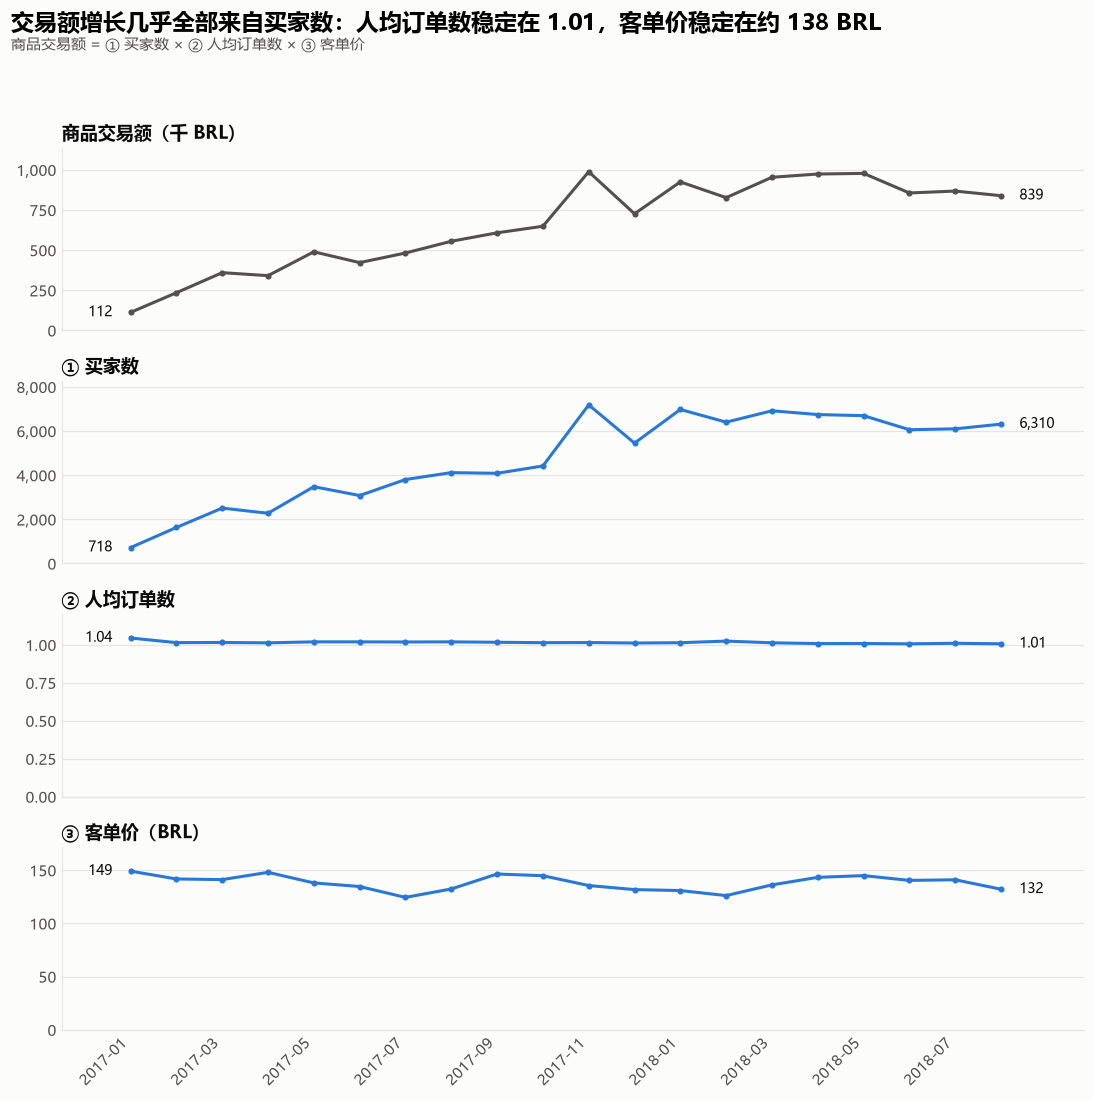

In [5]:
# 每个面板的设置：(列名, 标题, 缩放倍数, 数字格式, 颜色)
panels = [
    ("gmv_brl",          "商品交易额（千 BRL）", 1000, "{:,.0f}", COLORS["text_secondary"]),
    ("buyers",           "① 买家数",             1,    "{:,.0f}", COLORS["blue"]),
    ("orders_per_buyer", "② 人均订单数",         1,    "{:.2f}",  COLORS["blue"]),
    ("aov",              "③ 客单价（BRL）",      1,    "{:,.0f}", COLORS["blue"]),
]

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 10), sharex=True)

# 用循环逐个画面板，避免把同样的代码写4遍
for ax, (col, title, scale, fmt, color) in zip(axes, panels):
    values = df_kpi[col] / scale
    ax.plot(df_kpi["purchase_month"], values, color=color, marker="o", markersize=3)
    ax.set_title(title, fontsize=12)
    ax.set_ylim(0, values.max() * 1.15)          # 每个面板的纵轴都从0开始
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _, f=fmt: f.format(v)))
    # 在线的首尾标出起点和终点的数值
    first, last = values.iloc[0], values.iloc[-1]
    ax.text(len(df_kpi) - 0.6, last, fmt.format(last), va="center", fontsize=9, color=COLORS["text"])
    ax.text(-0.4, first, fmt.format(first), va="center", ha="right", fontsize=9, color=COLORS["text"])

axes[-1].set_xticks(range(0, len(df_kpi), 2))
axes[-1].set_xticklabels(df_kpi["purchase_month"][::2], rotation=45, ha="right")
axes[0].set_xlim(-1.5, len(df_kpi) + 0.8)

fig.suptitle("交易额增长几乎全部来自买家数：人均订单数稳定在 1.01，客单价稳定在约 138 BRL", x=0.01, y=0.995, ha="left", fontsize=15, fontweight="bold")
fig.text(0.01, 0.96, "商品交易额 = ① 买家数 × ② 人均订单数 × ③ 客单价", fontsize=10, color=COLORS["text_secondary"])
fig.tight_layout(rect=(0, 0, 1, 0.945))
fig.savefig("../docs/figures/m1_kpi_tree.png", dpi=150, bbox_inches="tight")
plt.show()